In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import yaml

yaml_file_path = "/content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml"

try:
    with open(yaml_file_path, 'r') as file:
        yaml_content = yaml.safe_load(file)
    print(f"Successfully read YAML file content:\n{yaml.dump(yaml_content, indent=2)}")
except FileNotFoundError:
    print(f"Error: The file '{yaml_file_path}' was not found. Please ensure the path is correct and Google Drive is mounted.")
except Exception as e:
    print(f"An error occurred while reading the YAML file: {e}")

Successfully read YAML file content:
names:
  0: lesion
path: /content/drive/MyDrive/oral_yolo_dataset
test: images/test
train: images/train
val: images/val



In [ ]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.2 MB/s eta 0:00:00


In [ ]:
print(f"Attempting to read: /content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml")
!cat /content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml

Attempting to read: /content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml
path: /content/drive/MyDrive/oral_yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: lesion


In [ ]:
from ultralytics import YOLO

DATA_YAML = "/content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml"
PROJECT_DIR = "/content/drive/MyDrive/oral_yolo_runs"

model = YOLO("yolo11n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    optimizer="AdamW",
    lr0=1e-3,
    weight_decay=5e-4,
    project=PROJECT_DIR,
    name="lesion_cropper_yolo11n",
    pretrained=True,
    single_cls=True,
    close_mosaic=10,
    device=0,
)

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=lesion_cropper_yolo11n-6, nbs=64, nms=False, opset=None, optimize=False, op

In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import pandas as pd
from ultralytics import YOLO


MODEL_PATH = "/content/drive/MyDrive/oral_yolo_runs/lesion_cropper_yolo11n-6/weights/best.pt"

SOURCE_IMAGES = Path("/content/drive/MyDrive/oral_yolo_dataset/images/test")

OUTPUT_CROPS = Path("/content/drive/MyDrive/oral_lesion_crops_224")

CROP_SIZE = 224
CONF_THRESHOLD = 0.15

# Important for Gemma/VLM context
BOX_EXPAND_RATIO = 0.60

MAX_CROPS_PER_IMAGE = 2


def expand_box(x1, y1, x2, y2, img_w, img_h, ratio=0.60):
    box_w = x2 - x1
    box_h = y2 - y1

    pad_w = box_w * ratio
    pad_h = box_h * ratio

    x1 = max(0, x1 - pad_w)
    y1 = max(0, y1 - pad_h)
    x2 = min(img_w, x2 + pad_w)
    y2 = min(img_h, y2 + pad_h)

    return x1, y1, x2, y2


def make_square_box(x1, y1, x2, y2, img_w, img_h):
    w = x2 - x1
    h = y2 - y1
    side = max(w, h)

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    sx1 = cx - side / 2
    sy1 = cy - side / 2
    sx2 = cx + side / 2
    sy2 = cy + side / 2

    if sx1 < 0:
        sx2 -= sx1
        sx1 = 0
    if sy1 < 0:
        sy2 -= sy1
        sy1 = 0
    if sx2 > img_w:
        shift = sx2 - img_w
        sx1 -= shift
        sx2 = img_w
    if sy2 > img_h:
        shift = sy2 - img_h
        sy1 -= shift
        sy2 = img_h

    sx1 = max(0, sx1)
    sy1 = max(0, sy1)
    sx2 = min(img_w, sx2)
    sy2 = min(img_h, sy2)

    return int(sx1), int(sy1), int(sx2), int(sy2)


def crop_with_context(image, box, expand_ratio=0.60):
    img_w, img_h = image.size

    x1, y1, x2, y2 = box

    x1, y1, x2, y2 = expand_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
        ratio=expand_ratio,
    )

    x1, y1, x2, y2 = make_square_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
    )

    crop = image.crop((x1, y1, x2, y2))
    crop = crop.resize((CROP_SIZE, CROP_SIZE), Image.BICUBIC)

    return crop, (x1, y1, x2, y2)


def generate_crops():
    OUTPUT_CROPS.mkdir(parents=True, exist_ok=True)

    model = YOLO(MODEL_PATH)

    image_paths = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
        image_paths.extend(list(SOURCE_IMAGES.glob(ext)))

    records = []

    for img_path in tqdm(image_paths):
        image = Image.open(img_path).convert("RGB")

        results = model.predict(
            source=str(img_path),
            imgsz=640,
            conf=CONF_THRESHOLD,
            iou=0.5,
            verbose=False,
        )

        boxes = results[0].boxes

        if boxes is None or len(boxes) == 0:
            records.append({
                "source_image": str(img_path),
                "crop_path": "",
                "detected": False,
                "confidence": 0.0,
            })
            continue

        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()

        order = confs.argsort()[::-1][:MAX_CROPS_PER_IMAGE]

        for crop_rank, idx in enumerate(order):
            raw_box = xyxy[idx]
            conf = float(confs[idx])

            crop, expanded_box = crop_with_context(
                image,
                raw_box,
                expand_ratio=BOX_EXPAND_RATIO,
            )

            out_name = f"{img_path.stem}_crop{crop_rank}_conf{conf:.2f}.jpg"
            out_path = OUTPUT_CROPS / out_name

            crop.save(out_path, quality=95)

            x1, y1, x2, y2 = expanded_box

            records.append({
                "source_image": str(img_path),
                "crop_path": str(out_path),
                "detected": True,
                "confidence": conf,
                "raw_x1": float(raw_box[0]),
                "raw_y1": float(raw_box[1]),
                "raw_x2": float(raw_box[2]),
                "raw_y2": float(raw_box[3]),
                "crop_x1": x1,
                "crop_y1": y1,
                "crop_x2": x2,
                "crop_y2": y2,
                "expand_ratio": BOX_EXPAND_RATIO,
            })

    df = pd.DataFrame(records)
    manifest_path = OUTPUT_CROPS / "crop_manifest.csv"
    df.to_csv(manifest_path, index=False)

    print("Saved crops:", OUTPUT_CROPS)
    print("Saved manifest:", manifest_path)
    print(df.head())


generate_crops()

100%|██████████| 47/47 [00:20<00:00,  2.33it/s]

Saved crops: /content/drive/MyDrive/oral_lesion_crops_224
Saved manifest: /content/drive/MyDrive/oral_lesion_crops_224/crop_manifest.csv
                                        source_image  \
0  /content/drive/MyDrive/oral_yolo_dataset/image...   
1  /content/drive/MyDrive/oral_yolo_dataset/image...   
2  /content/drive/MyDrive/oral_yolo_dataset/image...   
3  /content/drive/MyDrive/oral_yolo_dataset/image...   
4  /content/drive/MyDrive/oral_yolo_dataset/image...   

                                           crop_path  detected  confidence  \
0                                                        False    0.000000   
1                                                        False    0.000000   
2  /content/drive/MyDrive/oral_lesion_crops_224/o...      True    0.754269   
3  /content/drive/MyDrive/oral_lesion_crops_224/o...      True    0.646750   
4  /content/drive/MyDrive/oral_lesion_crops_224/v...      True    0.422889   

       raw_x1      raw_y1      raw_x2      raw_y2  crop_x

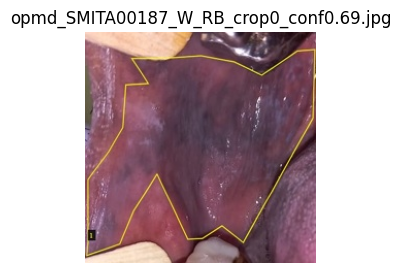

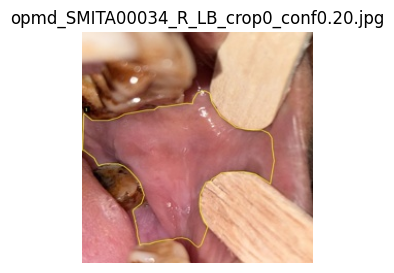

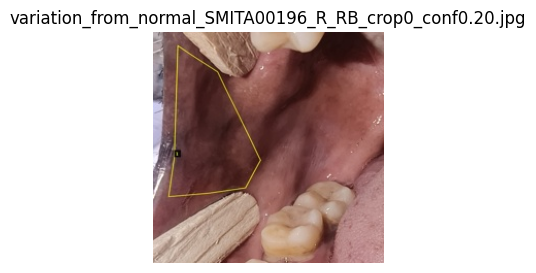

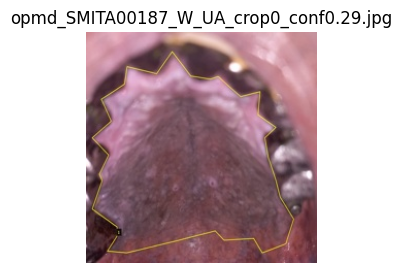

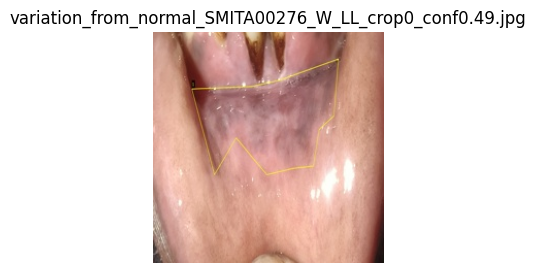

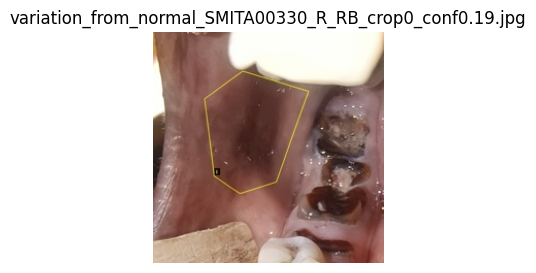

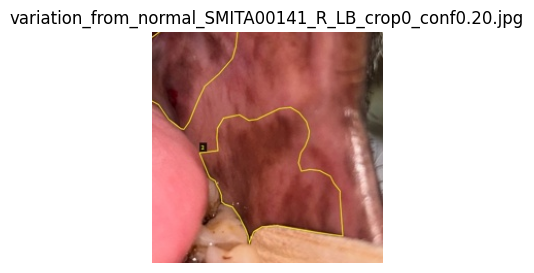

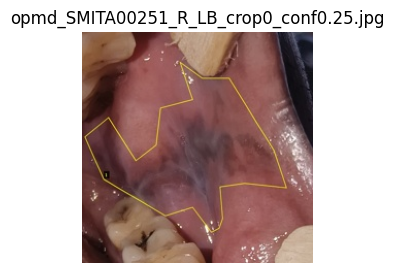

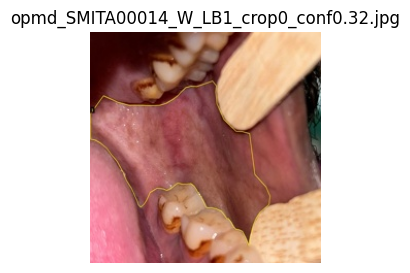

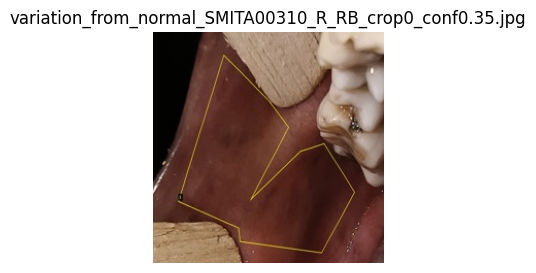

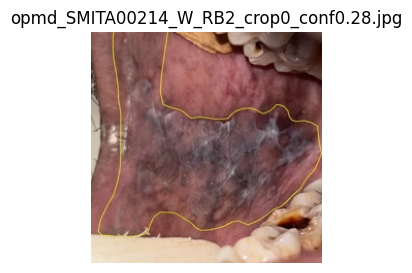

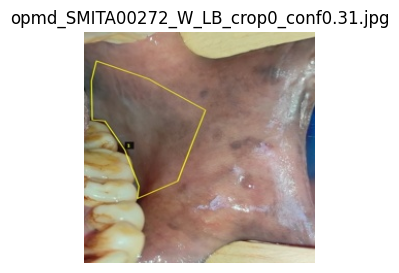

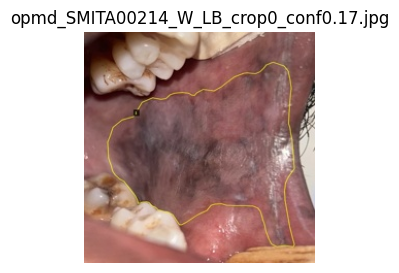

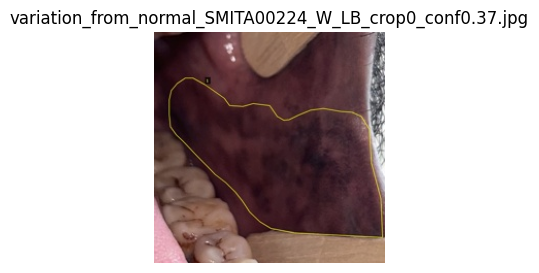

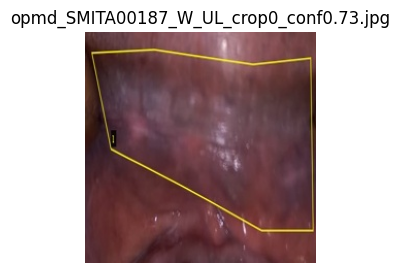

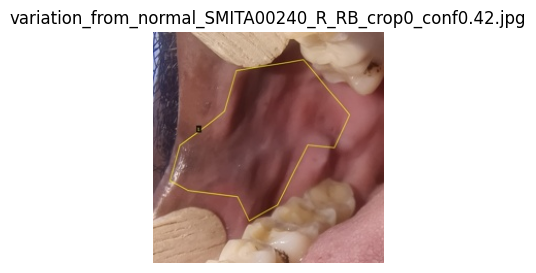

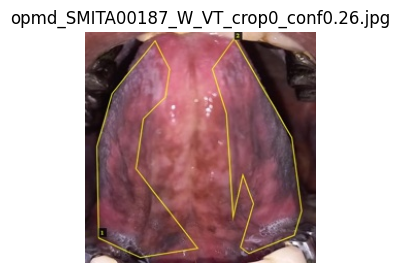

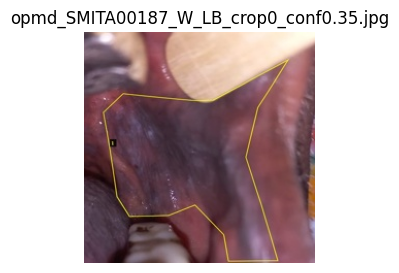

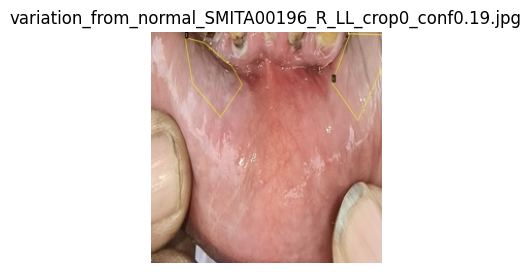

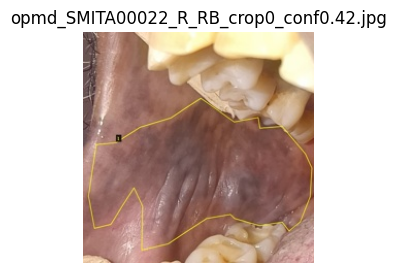

In [ ]:
from pathlib import Path
from PIL import Image
import random
import matplotlib.pyplot as plt

CROP_DIR = Path("/content/drive/MyDrive/oral_lesion_crops_224")

crop_paths = list(CROP_DIR.glob("*.jpg"))
sample = random.sample(crop_paths, min(20, len(crop_paths)))

for p in sample:
    img = Image.open(p).convert("RGB")
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.title(p.name)
    plt.axis("off")
    plt.show()

In [ ]:
import pandas as pd

manifest = pd.read_csv("/content/drive/MyDrive/oral_lesion_crops_224/crop_manifest.csv")

total = len(manifest)
detected = manifest["detected"].sum()
missed = total - detected

print("Total rows:", total)
print("Detected rows:", detected)
print("Missed rows:", missed)
print("Detection rate:", detected / total)

print("\nConfidence summary:")
print(manifest[manifest["detected"] == True]["confidence"].describe())

Total rows: 48
Detected rows: 31
Missed rows: 17
Detection rate: 0.6458333333333334

Confidence summary:
count    31.000000
mean      0.334515
std       0.171737
min       0.151264
25%       0.197501
50%       0.293796
75%       0.385386
max       0.754269
Name: confidence, dtype: float64


In [ ]:
image_level = manifest.groupby("source_image")["detected"].max()

print("Total source images:", len(image_level))
print("Images with detection:", image_level.sum())
print("Images missed:", len(image_level) - image_level.sum())
print("Image-level detection rate:", image_level.mean())

Total source images: 47
Images with detection: 30
Images missed: 17
Image-level detection rate: 0.6382978723404256


In [ ]:
from pathlib import Path
import shutil
import pandas as pd

manifest = pd.read_csv("/content/drive/MyDrive/oral_lesion_crops_224/crop_manifest.csv")

missed = manifest[manifest["detected"] == False]

MISS_DIR = Path("/content/drive/MyDrive/oral_lesion_missed_cases")
MISS_DIR.mkdir(parents=True, exist_ok=True)

for src in missed["source_image"].dropna().unique():
    src_path = Path(src)
    if src_path.exists():
        shutil.copy2(src_path, MISS_DIR / src_path.name)

print("Saved missed cases to:", MISS_DIR)
print("Missed images:", len(missed))

Saved missed cases to: /content/drive/MyDrive/oral_lesion_missed_cases
Missed images: 17


In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import pandas as pd
from ultralytics import YOLO


MODEL_PATH = "/content/drive/MyDrive/oral_yolo_runs/lesion_cropper_yolo11n-6/weights/best.pt"

YOLO_DATASET_ROOT = Path("/content/drive/MyDrive/oral_yolo_dataset")
OUTPUT_ROOT = Path("/content/drive/MyDrive/oral_lesion_crops_224_all")

CROP_SIZE = 224
CONF_THRESHOLD = 0.15
BOX_EXPAND_RATIO = 0.60
MAX_CROPS_PER_IMAGE = 2


def expand_box(x1, y1, x2, y2, img_w, img_h, ratio=0.60):
    box_w = x2 - x1
    box_h = y2 - y1

    pad_w = box_w * ratio
    pad_h = box_h * ratio

    x1 = max(0, x1 - pad_w)
    y1 = max(0, y1 - pad_h)
    x2 = min(img_w, x2 + pad_w)
    y2 = min(img_h, y2 + pad_h)

    return x1, y1, x2, y2


def make_square_box(x1, y1, x2, y2, img_w, img_h):
    w = x2 - x1
    h = y2 - y1
    side = max(w, h)

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    sx1 = cx - side / 2
    sy1 = cy - side / 2
    sx2 = cx + side / 2
    sy2 = cy + side / 2

    if sx1 < 0:
        sx2 -= sx1
        sx1 = 0
    if sy1 < 0:
        sy2 -= sy1
        sy1 = 0
    if sx2 > img_w:
        shift = sx2 - img_w
        sx1 -= shift
        sx2 = img_w
    if sy2 > img_h:
        shift = sy2 - img_h
        sy1 -= shift
        sy2 = img_h

    sx1 = max(0, sx1)
    sy1 = max(0, sy1)
    sx2 = min(img_w, sx2)
    sy2 = min(img_h, sy2)

    return int(sx1), int(sy1), int(sx2), int(sy2)


def crop_with_context(image, box):
    img_w, img_h = image.size

    x1, y1, x2, y2 = box

    x1, y1, x2, y2 = expand_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
        ratio=BOX_EXPAND_RATIO,
    )

    x1, y1, x2, y2 = make_square_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
    )

    crop = image.crop((x1, y1, x2, y2))
    crop = crop.resize((CROP_SIZE, CROP_SIZE), Image.BICUBIC)

    return crop, (x1, y1, x2, y2)


def collect_images(folder):
    paths = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
        paths.extend(list(folder.glob(ext)))
    return paths


def generate_split_crops(split, model):
    source_dir = YOLO_DATASET_ROOT / "images" / split
    output_dir = OUTPUT_ROOT / split
    output_dir.mkdir(parents=True, exist_ok=True)

    image_paths = collect_images(source_dir)

    print(f"\nSplit: {split}")
    print("Images:", len(image_paths))

    records = []

    for img_path in tqdm(image_paths):
        image = Image.open(img_path).convert("RGB")

        results = model.predict(
            source=str(img_path),
            imgsz=640,
            conf=CONF_THRESHOLD,
            iou=0.5,
            verbose=False,
        )

        boxes = results[0].boxes

        if boxes is None or len(boxes) == 0:
            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": "",
                "detected": False,
                "confidence": 0.0,
                "expand_ratio": None,
            })
            continue

        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()

        order = confs.argsort()[::-1][:MAX_CROPS_PER_IMAGE]

        for crop_rank, idx in enumerate(order):
            raw_box = xyxy[idx]
            conf = float(confs[idx])

            crop, expanded_box = crop_with_context(image, raw_box)

            out_name = f"{img_path.stem}_crop{crop_rank}_conf{conf:.2f}.jpg"
            out_path = output_dir / out_name

            crop.save(out_path, quality=95)

            x1, y1, x2, y2 = expanded_box

            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": str(out_path),
                "detected": True,
                "confidence": conf,
                "raw_x1": float(raw_box[0]),
                "raw_y1": float(raw_box[1]),
                "raw_x2": float(raw_box[2]),
                "raw_y2": float(raw_box[3]),
                "crop_x1": x1,
                "crop_y1": y1,
                "crop_x2": x2,
                "crop_y2": y2,
                "expand_ratio": BOX_EXPAND_RATIO,
            })

    return records


def main():
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

    model = YOLO(MODEL_PATH)

    all_records = []

    for split in ["train", "val", "test"]:
        split_records = generate_split_crops(split, model)
        all_records.extend(split_records)

    manifest = pd.DataFrame(all_records)
    manifest_path = OUTPUT_ROOT / "crop_manifest_all.csv"
    manifest.to_csv(manifest_path, index=False)

    print("\nSaved all crops to:", OUTPUT_ROOT)
    print("Saved manifest:", manifest_path)

    print("\nImage-level detection rate:")
    print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))

    print("\nCrop-level confidence:")
    print(manifest[manifest["detected"] == True].groupby("split")["confidence"].describe())


main()


Split: train
Images: 182


100%|██████████| 182/182 [00:07<00:00, 25.43it/s]



Split: val
Images: 44


100%|██████████| 44/44 [00:01<00:00, 29.35it/s]



Split: test
Images: 47


100%|██████████| 47/47 [00:01<00:00, 25.06it/s]


Saved all crops to: /content/drive/MyDrive/oral_lesion_crops_224_all
Saved manifest: /content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_all.csv

Image-level detection rate:
split
test     0.638298
train    0.609890
val      0.636364
dtype: float64

Crop-level confidence:
       count      mean       std       min       25%       50%       75%  \
split                                                                      
test    31.0  0.334515  0.171737  0.151264  0.197501  0.293796  0.385386   
train  128.0  0.383000  0.191551  0.150502  0.223537  0.339165  0.487747   
val     29.0  0.395836  0.199711  0.154682  0.233643  0.342385  0.525213   

            max  
split            
test   0.754269  
train  0.942150  
val    0.798625  



/tmp/ipykernel_3816/2569838757.py:194: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))


#Second Training

In [ ]:
from ultralytics import YOLO

DATA_YAML = "/content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml"
PROJECT_DIR = "/content/drive/MyDrive/oral_yolo_runs"

model = YOLO("yolo11n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=200,
    imgsz=640,
    batch=8,
    patience=40,
    optimizer="AdamW",
    lr0=5e-4,
    weight_decay=5e-4,
    project=PROJECT_DIR,
    name="lesion_cropper_yolo11n_recall_v2",
    pretrained=True,
    single_cls=True,
    close_mosaic=20,
    device=0,
)

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=lesion_cropper_yolo11n_recall_v2, nbs=64, nms=False, opset=None, optimize=F

In [ ]:
from pathlib import Path
import shutil
import pandas as pd

manifest = pd.read_csv("/content/drive/MyDrive/oral_lesion_crops_224/crop_manifest.csv")

missed = manifest[manifest["detected"] == False]

MISS_DIR = Path("/content/drive/MyDrive/oral_lesion_missed_cases")
MISS_DIR.mkdir(parents=True, exist_ok=True)

for src in missed["source_image"].dropna().unique():
    src_path = Path(src)
    if src_path.exists():
        shutil.copy2(src_path, MISS_DIR / src_path.name)

print("Saved missed cases to:", MISS_DIR)
print("Missed source images:", missed["source_image"].nunique())

Saved missed cases to: /content/drive/MyDrive/oral_lesion_missed_cases
Missed source images: 17


In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import pandas as pd
from ultralytics import YOLO


MODEL_PATH = "/content/drive/MyDrive/oral_yolo_runs/lesion_cropper_yolo11n_recall_v2/weights/best.pt"

YOLO_DATASET_ROOT = Path("/content/drive/MyDrive/oral_yolo_dataset")
OUTPUT_ROOT = Path("/content/drive/MyDrive/oral_lesion_crops_224_all")

CROP_SIZE = 224
CONF_THRESHOLD = 0.10
BOX_EXPAND_RATIO = 0.60
MAX_CROPS_PER_IMAGE = 2


def expand_box(x1, y1, x2, y2, img_w, img_h, ratio=0.60):
    box_w = x2 - x1
    box_h = y2 - y1

    pad_w = box_w * ratio
    pad_h = box_h * ratio

    x1 = max(0, x1 - pad_w)
    y1 = max(0, y1 - pad_h)
    x2 = min(img_w, x2 + pad_w)
    y2 = min(img_h, y2 + pad_h)

    return x1, y1, x2, y2


def make_square_box(x1, y1, x2, y2, img_w, img_h):
    w = x2 - x1
    h = y2 - y1
    side = max(w, h)

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    sx1 = cx - side / 2
    sy1 = cy - side / 2
    sx2 = cx + side / 2
    sy2 = cy + side / 2

    if sx1 < 0:
        sx2 -= sx1
        sx1 = 0
    if sy1 < 0:
        sy2 -= sy1
        sy1 = 0
    if sx2 > img_w:
        shift = sx2 - img_w
        sx1 -= shift
        sx2 = img_w
    if sy2 > img_h:
        shift = sy2 - img_h
        sy1 -= shift
        sy2 = img_h

    sx1 = max(0, sx1)
    sy1 = max(0, sy1)
    sx2 = min(img_w, sx2)
    sy2 = min(img_h, sy2)

    return int(sx1), int(sy1), int(sx2), int(sy2)


def crop_with_context(image, box):
    img_w, img_h = image.size

    x1, y1, x2, y2 = box

    x1, y1, x2, y2 = expand_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
        ratio=BOX_EXPAND_RATIO,
    )

    x1, y1, x2, y2 = make_square_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
    )

    crop = image.crop((x1, y1, x2, y2))
    crop = crop.resize((CROP_SIZE, CROP_SIZE), Image.BICUBIC)

    return crop, (x1, y1, x2, y2)


def collect_images(folder):
    paths = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
        paths.extend(list(folder.glob(ext)))
    return paths


def generate_split_crops(split, model):
    source_dir = YOLO_DATASET_ROOT / "images" / split
    output_dir = OUTPUT_ROOT / split
    output_dir.mkdir(parents=True, exist_ok=True)

    image_paths = collect_images(source_dir)

    print(f"\nSplit: {split}")
    print("Images:", len(image_paths))

    records = []

    for img_path in tqdm(image_paths):
        image = Image.open(img_path).convert("RGB")

        results = model.predict(
            source=str(img_path),
            imgsz=640,
            conf=CONF_THRESHOLD,
            iou=0.5,
            verbose=False,
        )

        boxes = results[0].boxes

        if boxes is None or len(boxes) == 0:
            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": "",
                "detected": False,
                "confidence": 0.0,
                "expand_ratio": None,
            })
            continue

        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()

        order = confs.argsort()[::-1][:MAX_CROPS_PER_IMAGE]

        for crop_rank, idx in enumerate(order):
            raw_box = xyxy[idx]
            conf = float(confs[idx])

            crop, expanded_box = crop_with_context(image, raw_box)

            out_name = f"{img_path.stem}_crop{crop_rank}_conf{conf:.2f}.jpg"
            out_path = output_dir / out_name

            crop.save(out_path, quality=95)

            x1, y1, x2, y2 = expanded_box

            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": str(out_path),
                "detected": True,
                "confidence": conf,
                "raw_x1": float(raw_box[0]),
                "raw_y1": float(raw_box[1]),
                "raw_x2": float(raw_box[2]),
                "raw_y2": float(raw_box[3]),
                "crop_x1": x1,
                "crop_y1": y1,
                "crop_x2": x2,
                "crop_y2": y2,
                "expand_ratio": BOX_EXPAND_RATIO,
            })

    return records


def main():
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

    model = YOLO(MODEL_PATH)

    all_records = []

    for split in ["train", "val", "test"]:
        split_records = generate_split_crops(split, model)
        all_records.extend(split_records)

    manifest = pd.DataFrame(all_records)
    manifest_path = OUTPUT_ROOT / "crop_manifest_all.csv"
    manifest.to_csv(manifest_path, index=False)

    print("\nSaved all crops to:", OUTPUT_ROOT)
    print("Saved manifest:", manifest_path)

    print("\nImage-level detection rate:")
    print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))

    print("\nCrop-level confidence:")
    print(manifest[manifest["detected"] == True].groupby("split")["confidence"].describe())


main()


Split: train
Images: 182


100%|██████████| 182/182 [00:07<00:00, 24.70it/s]



Split: val
Images: 44


100%|██████████| 44/44 [00:01<00:00, 26.54it/s]



Split: test
Images: 47


100%|██████████| 47/47 [00:01<00:00, 26.27it/s]


Saved all crops to: /content/drive/MyDrive/oral_lesion_crops_224_all
Saved manifest: /content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_all.csv

Image-level detection rate:
split
test     1.000000
train    0.983516
val      0.977273
dtype: float64

Crop-level confidence:
       count      mean       std       min       25%       50%       75%  \
split                                                                      
test    65.0  0.488814  0.280873  0.104107  0.222148  0.449704  0.750322   
train  242.0  0.601859  0.305403  0.101982  0.277698  0.670949  0.893811   
val     55.0  0.521732  0.244631  0.100339  0.384702  0.482153  0.713782   

            max  
split            
test   0.954924  
train  0.984034  
val    0.965907  



/tmp/ipykernel_3816/3376891458.py:194: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))


In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import pandas as pd
from ultralytics import YOLO


MODEL_PATH = "/content/drive/MyDrive/oral_yolo_runs/lesion_cropper_yolo11n_recall_v2/weights/best.pt"

YOLO_DATASET_ROOT = Path("/content/drive/MyDrive/oral_yolo_dataset")
OUTPUT_ROOT = Path("/content/drive/MyDrive/oral_lesion_crops_224_all")

CROP_SIZE = 224
CONF_THRESHOLD = 0.15
BOX_EXPAND_RATIO = 0.60
MAX_CROPS_PER_IMAGE = 2


def expand_box(x1, y1, x2, y2, img_w, img_h, ratio=0.60):
    box_w = x2 - x1
    box_h = y2 - y1

    pad_w = box_w * ratio
    pad_h = box_h * ratio

    x1 = max(0, x1 - pad_w)
    y1 = max(0, y1 - pad_h)
    x2 = min(img_w, x2 + pad_w)
    y2 = min(img_h, y2 + pad_h)

    return x1, y1, x2, y2


def make_square_box(x1, y1, x2, y2, img_w, img_h):
    w = x2 - x1
    h = y2 - y1
    side = max(w, h)

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    sx1 = cx - side / 2
    sy1 = cy - side / 2
    sx2 = cx + side / 2
    sy2 = cy + side / 2

    if sx1 < 0:
        sx2 -= sx1
        sx1 = 0
    if sy1 < 0:
        sy2 -= sy1
        sy1 = 0
    if sx2 > img_w:
        shift = sx2 - img_w
        sx1 -= shift
        sx2 = img_w
    if sy2 > img_h:
        shift = sy2 - img_h
        sy1 -= shift
        sy2 = img_h

    sx1 = max(0, sx1)
    sy1 = max(0, sy1)
    sx2 = min(img_w, sx2)
    sy2 = min(img_h, sy2)

    return int(sx1), int(sy1), int(sx2), int(sy2)


def crop_with_context(image, box):
    img_w, img_h = image.size

    x1, y1, x2, y2 = box

    x1, y1, x2, y2 = expand_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
        ratio=BOX_EXPAND_RATIO,
    )

    x1, y1, x2, y2 = make_square_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
    )

    crop = image.crop((x1, y1, x2, y2))
    crop = crop.resize((CROP_SIZE, CROP_SIZE), Image.BICUBIC)

    return crop, (x1, y1, x2, y2)


def collect_images(folder):
    paths = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
        paths.extend(list(folder.glob(ext)))
    return paths


def generate_split_crops(split, model):
    source_dir = YOLO_DATASET_ROOT / "images" / split
    output_dir = OUTPUT_ROOT / split
    output_dir.mkdir(parents=True, exist_ok=True)

    image_paths = collect_images(source_dir)

    print(f"\nSplit: {split}")
    print("Images:", len(image_paths))

    records = []

    for img_path in tqdm(image_paths):
        image = Image.open(img_path).convert("RGB")

        results = model.predict(
            source=str(img_path),
            imgsz=640,
            conf=CONF_THRESHOLD,
            iou=0.5,
            verbose=False,
        )

        boxes = results[0].boxes

        if boxes is None or len(boxes) == 0:
            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": "",
                "detected": False,
                "confidence": 0.0,
                "expand_ratio": None,
            })
            continue

        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()

        order = confs.argsort()[::-1][:MAX_CROPS_PER_IMAGE]

        for crop_rank, idx in enumerate(order):
            raw_box = xyxy[idx]
            conf = float(confs[idx])

            crop, expanded_box = crop_with_context(image, raw_box)

            out_name = f"{img_path.stem}_crop{crop_rank}_conf{conf:.2f}.jpg"
            out_path = output_dir / out_name

            crop.save(out_path, quality=95)

            x1, y1, x2, y2 = expanded_box

            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": str(out_path),
                "detected": True,
                "confidence": conf,
                "raw_x1": float(raw_box[0]),
                "raw_y1": float(raw_box[1]),
                "raw_x2": float(raw_box[2]),
                "raw_y2": float(raw_box[3]),
                "crop_x1": x1,
                "crop_y1": y1,
                "crop_x2": x2,
                "crop_y2": y2,
                "expand_ratio": BOX_EXPAND_RATIO,
            })

    return records


def main():
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

    model = YOLO(MODEL_PATH)

    all_records = []

    for split in ["train", "val", "test"]:
        split_records = generate_split_crops(split, model)
        all_records.extend(split_records)

    manifest = pd.DataFrame(all_records)
    manifest_path = OUTPUT_ROOT / "crop_manifest_all.csv"
    manifest.to_csv(manifest_path, index=False)

    print("\nSaved all crops to:", OUTPUT_ROOT)
    print("Saved manifest:", manifest_path)

    print("\nImage-level detection rate:")
    print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))

    print("\nCrop-level confidence:")
    print(manifest[manifest["detected"] == True].groupby("split")["confidence"].describe())


main()


Split: train
Images: 182


100%|██████████| 182/182 [00:08<00:00, 22.00it/s]



Split: val
Images: 44


100%|██████████| 44/44 [00:01<00:00, 24.20it/s]



Split: test
Images: 47


100%|██████████| 47/47 [00:01<00:00, 24.42it/s]


Saved all crops to: /content/drive/MyDrive/oral_lesion_crops_224_all
Saved manifest: /content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_all.csv

Image-level detection rate:
split
test     0.978723
train    0.961538
val      0.977273
dtype: float64

Crop-level confidence:
       count      mean       std       min       25%       50%       75%  \
split                                                                      
test    57.0  0.540715  0.260513  0.158023  0.295877  0.550412  0.778593   
train  221.0  0.647494  0.279362  0.150423  0.409636  0.731065  0.901868   
val     50.0  0.563410  0.215525  0.203316  0.423372  0.495868  0.722480   

            max  
split            
test   0.954924  
train  0.984034  
val    0.965907  



/tmp/ipykernel_3816/1561391829.py:194: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))


#Third try

In [ ]:
from ultralytics import YOLO

DATA_YAML = "/content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml"
PROJECT_DIR = "/content/drive/MyDrive/oral_yolo_runs"

model = YOLO("yolo11s.pt")

results = model.train(
    data=DATA_YAML,
    epochs=200,
    imgsz=640,
    batch=8,
    patience=40,
    optimizer="AdamW",
    lr0=5e-4,
    weight_decay=5e-4,
    project=PROJECT_DIR,
    name="lesion_cropper_yolo11n_recall_v2",
    pretrained=True,
    single_cls=True,
    close_mosaic=20,
    device=0,
)

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/oral_yolo_dataset/oral_lesion.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=lesion_cropper_yolo11n_recall_v2-2, nbs=64, nms=False, opset=None, optimize

In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import pandas as pd
from ultralytics import YOLO


MODEL_PATH = "/content/drive/MyDrive/oral_yolo_runs/lesion_cropper_yolo11n_recall_v2-2/weights/best.pt"

YOLO_DATASET_ROOT = Path("/content/drive/MyDrive/oral_yolo_dataset")
OUTPUT_ROOT = Path("/content/drive/MyDrive/oral_lesion_crops_224_all")

CROP_SIZE = 224
CONF_THRESHOLD = 0.10
BOX_EXPAND_RATIO = 0.60
MAX_CROPS_PER_IMAGE = 2


def expand_box(x1, y1, x2, y2, img_w, img_h, ratio=0.60):
    box_w = x2 - x1
    box_h = y2 - y1

    pad_w = box_w * ratio
    pad_h = box_h * ratio

    x1 = max(0, x1 - pad_w)
    y1 = max(0, y1 - pad_h)
    x2 = min(img_w, x2 + pad_w)
    y2 = min(img_h, y2 + pad_h)

    return x1, y1, x2, y2


def make_square_box(x1, y1, x2, y2, img_w, img_h):
    w = x2 - x1
    h = y2 - y1
    side = max(w, h)

    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    sx1 = cx - side / 2
    sy1 = cy - side / 2
    sx2 = cx + side / 2
    sy2 = cy + side / 2

    if sx1 < 0:
        sx2 -= sx1
        sx1 = 0
    if sy1 < 0:
        sy2 -= sy1
        sy1 = 0
    if sx2 > img_w:
        shift = sx2 - img_w
        sx1 -= shift
        sx2 = img_w
    if sy2 > img_h:
        shift = sy2 - img_h
        sy1 -= shift
        sy2 = img_h

    sx1 = max(0, sx1)
    sy1 = max(0, sy1)
    sx2 = min(img_w, sx2)
    sy2 = min(img_h, sy2)

    return int(sx1), int(sy1), int(sx2), int(sy2)


def crop_with_context(image, box):
    img_w, img_h = image.size

    x1, y1, x2, y2 = box

    x1, y1, x2, y2 = expand_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
        ratio=BOX_EXPAND_RATIO,
    )

    x1, y1, x2, y2 = make_square_box(
        x1, y1, x2, y2,
        img_w=img_w,
        img_h=img_h,
    )

    crop = image.crop((x1, y1, x2, y2))
    crop = crop.resize((CROP_SIZE, CROP_SIZE), Image.BICUBIC)

    return crop, (x1, y1, x2, y2)


def collect_images(folder):
    paths = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
        paths.extend(list(folder.glob(ext)))
    return paths


def generate_split_crops(split, model):
    source_dir = YOLO_DATASET_ROOT / "images" / split
    output_dir = OUTPUT_ROOT / split
    output_dir.mkdir(parents=True, exist_ok=True)

    image_paths = collect_images(source_dir)

    print(f"\nSplit: {split}")
    print("Images:", len(image_paths))

    records = []

    for img_path in tqdm(image_paths):
        image = Image.open(img_path).convert("RGB")

        results = model.predict(
            source=str(img_path),
            imgsz=640,
            conf=CONF_THRESHOLD,
            iou=0.5,
            verbose=False,
        )

        boxes = results[0].boxes

        if boxes is None or len(boxes) == 0:
            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": "",
                "detected": False,
                "confidence": 0.0,
                "expand_ratio": None,
            })
            continue

        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()

        order = confs.argsort()[::-1][:MAX_CROPS_PER_IMAGE]

        for crop_rank, idx in enumerate(order):
            raw_box = xyxy[idx]
            conf = float(confs[idx])

            crop, expanded_box = crop_with_context(image, raw_box)

            out_name = f"{img_path.stem}_crop{crop_rank}_conf{conf:.2f}.jpg"
            out_path = output_dir / out_name

            crop.save(out_path, quality=95)

            x1, y1, x2, y2 = expanded_box

            records.append({
                "split": split,
                "source_image": str(img_path),
                "crop_path": str(out_path),
                "detected": True,
                "confidence": conf,
                "raw_x1": float(raw_box[0]),
                "raw_y1": float(raw_box[1]),
                "raw_x2": float(raw_box[2]),
                "raw_y2": float(raw_box[3]),
                "crop_x1": x1,
                "crop_y1": y1,
                "crop_x2": x2,
                "crop_y2": y2,
                "expand_ratio": BOX_EXPAND_RATIO,
            })

    return records


def main():
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

    model = YOLO(MODEL_PATH)

    all_records = []

    for split in ["train", "val", "test"]:
        split_records = generate_split_crops(split, model)
        all_records.extend(split_records)

    manifest = pd.DataFrame(all_records)
    manifest_path = OUTPUT_ROOT / "crop_manifest_all.csv"
    manifest.to_csv(manifest_path, index=False)

    print("\nSaved all crops to:", OUTPUT_ROOT)
    print("Saved manifest:", manifest_path)

    print("\nImage-level detection rate:")
    print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))

    print("\nCrop-level confidence:")
    print(manifest[manifest["detected"] == True].groupby("split")["confidence"].describe())


main()


Split: train
Images: 182


100%|██████████| 182/182 [00:10<00:00, 16.75it/s]



Split: val
Images: 44


100%|██████████| 44/44 [00:01<00:00, 22.46it/s]



Split: test
Images: 47


100%|██████████| 47/47 [00:02<00:00, 21.60it/s]


Saved all crops to: /content/drive/MyDrive/oral_lesion_crops_224_all
Saved manifest: /content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_all.csv

Image-level detection rate:
split
test     0.957447
train    0.928571
val      0.909091
dtype: float64

Crop-level confidence:
       count      mean       std       min       25%       50%       75%  \
split                                                                      
test    62.0  0.358567  0.213735  0.104436  0.153985  0.325535  0.517601   
train  212.0  0.435613  0.233674  0.100654  0.215292  0.432022  0.644825   
val     49.0  0.373706  0.210755  0.120597  0.180797  0.328883  0.525103   

            max  
split            
test   0.797847  
train  0.874930  
val    0.846736  



/tmp/ipykernel_3816/795291383.py:194: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(manifest.groupby("split").apply(lambda x: x.groupby("source_image")["detected"].max().mean()))


#Freezing the Second Model

In [ ]:
import shutil
from pathlib import Path

BEST_MODEL = Path("/content/drive/MyDrive/oral_yolo_runs/lesion_cropper_yolo11n_recall_v2/weights/best.pt")
FINAL_MODEL = Path("/content/drive/MyDrive/oral_cropper_yolo11n_best.pt")

shutil.copy2(BEST_MODEL, FINAL_MODEL)

print("Saved final cropper:", FINAL_MODEL)

Saved final cropper: /content/drive/MyDrive/oral_cropper_yolo11n_best.pt


In [ ]:
import pandas as pd

manifest = pd.read_csv("/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_all.csv")

detected = manifest[manifest["detected"] == True]

print("Total rows:", len(manifest))
print("Detected crop rows:", len(detected))
print("Unique source images:", manifest["source_image"].nunique())
print("Detected source images:", detected["source_image"].nunique())

print("\nDetected crops per split:")
print(detected["split"].value_counts())

print("\nConfidence by split:")
print(detected.groupby("split")["confidence"].describe())

Total rows: 366
Detected crop rows: 362
Unique source images: 273
Detected source images: 269

Detected crops per split:
split
train    242
test      65
val       55
Name: count, dtype: int64

Confidence by split:
       count      mean       std       min       25%       50%       75%  \
split                                                                      
test    65.0  0.488814  0.280873  0.104107  0.222148  0.449704  0.750322   
train  242.0  0.601859  0.305403  0.101982  0.277698  0.670949  0.893811   
val     55.0  0.521732  0.244631  0.100339  0.384702  0.482153  0.713782   

            max  
split            
test   0.954924  
train  0.984034  
val    0.965907  


#Attach labels to crops

In [ ]:
import pandas as pd
from pathlib import Path

crop_manifest_path = "/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_all.csv"
yolo_manifest_path = "/content/drive/MyDrive/oral_yolo_dataset/manifest.csv"

crops = pd.read_csv(crop_manifest_path)
yolo = pd.read_csv(yolo_manifest_path)

# Keep only successful crops
crops = crops[crops["detected"] == True].copy()

# Normalize paths for joining
crops["source_image_norm"] = crops["source_image"].apply(lambda x: str(Path(x)))
yolo["image_path_norm"] = yolo["image_path"].apply(lambda x: str(Path(x)))

merged = crops.merge(
    yolo[["image_path_norm", "source_class", "subject_id", "json_path", "source_image"]],
    left_on="source_image_norm",
    right_on="image_path_norm",
    how="left",
    suffixes=("_crop", "_yolo")
)

print("Crops:", len(crops))
print("Merged:", len(merged))
print("Missing labels:", merged["source_class"].isna().sum())

print("\nClass counts:")
print(merged["source_class"].value_counts())

out_path = "/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_labeled.csv"
merged.to_csv(out_path, index=False)

print("Saved:", out_path)

Crops: 362
Merged: 364
Missing labels: 0

Class counts:
source_class
variation_from_normal    201
opmd                     146
oral_cancer               17
Name: count, dtype: int64
Saved: /content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_labeled.csv


In [ ]:
import json
import pandas as pd
from pathlib import Path

labeled_manifest = "/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_labeled.csv"
output_jsonl = "/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_oral_lesion_dataset.jsonl"

df = pd.read_csv(labeled_manifest)
df = df[df["detected"] == True].copy()
df = df.dropna(subset=["crop_path", "source_class"])

def make_response(source_class):
    if source_class == "variation_from_normal":
        return (
            "The cropped oral mucosal region shows a variation from normal appearance. "
            "This should be treated as a low-to-moderate concern finding depending on symptoms and persistence. "
            "If the lesion is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended. "
            "This is not a medical diagnosis."
        )

    if source_class == "opmd":
        return (
            "The cropped oral mucosal region shows features consistent with an oral potentially malignant disorder category. "
            "This should be referred for clinical evaluation because OPMD lesions can require monitoring, biopsy, or specialist review. "
            "This is not a medical diagnosis."
        )

    if source_class == "oral_cancer":
        return (
            "The cropped oral mucosal region belongs to a high-risk oral cancer category in the training data. "
            "This should be treated as urgent referral for clinical examination and possible biopsy. "
            "This is not a medical diagnosis."
        )

    return (
        "The cropped oral mucosal region shows an abnormal finding. "
        "Clinical review is recommended if symptoms persist. "
        "This is not a medical diagnosis."
    )

def make_category(source_class):
    if source_class == "variation_from_normal":
        return "variation_from_normal"
    if source_class == "opmd":
        return "opmd_refer"
    if source_class == "oral_cancer":
        return "oral_cancer_suspicion"
    return "uncertain"

records = []

for _, row in df.iterrows():
    crop_path = row["crop_path"]
    source_class = row["source_class"]

    record = {
        "image": crop_path,
        "messages": [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": (
                            "Analyze this cropped oral mucosal lesion image. "
                            "Classify it into one of: variation_from_normal, opmd_refer, oral_cancer_suspicion. "
                            "Give a short risk-aware explanation and referral recommendation."
                        )
                    },
                    {
                        "type": "image",
                        "image": crop_path
                    }
                ]
            },
            {
                "role": "assistant",
                "content": json.dumps({
                    "category": make_category(source_class),
                    "source_label": source_class,
                    "recommendation": make_response(source_class)
                }, ensure_ascii=False)
            }
        ],
        "metadata": {
            "split": row["split"],
            "detector_confidence": float(row["confidence"]),
            "source_class": source_class,
            "source_image": row.get("source_image_crop", row.get("source_image", "")),
            "crop_path": crop_path
        }
    }

    records.append(record)

with open(output_jsonl, "w") as f:
    for r in records:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print("Saved JSONL:", output_jsonl)
print("Records:", len(records))

print("\nCounts:")
print(df["source_class"].value_counts())

Saved JSONL: /content/drive/MyDrive/oral_lesion_crops_224_all/gemma_oral_lesion_dataset.jsonl
Records: 364

Counts:
source_class
variation_from_normal    201
opmd                     146
oral_cancer               17
Name: count, dtype: int64


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_labeled.csv")
df = df[df["detected"] == True]

print(df["source_class"].value_counts())
print(df.groupby(["split", "source_class"]).size())

source_class
variation_from_normal    201
opmd                     146
oral_cancer               17
Name: count, dtype: int64
split  source_class         
test   opmd                      39
       oral_cancer                4
       variation_from_normal     22
train  opmd                      89
       oral_cancer               13
       variation_from_normal    142
val    opmd                      18
       variation_from_normal     37
dtype: int64


In [ ]:
import json
import pandas as pd
from pathlib import Path

LABELED_MANIFEST = "/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_labeled.csv"

OUT_DIR = Path("/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset")
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_JSONL_ALL = OUT_DIR / "gemma_oral_lesion_all.jsonl"
OUT_JSONL_TRAIN = OUT_DIR / "gemma_oral_lesion_train.jsonl"
OUT_JSONL_VAL = OUT_DIR / "gemma_oral_lesion_val.jsonl"
OUT_JSONL_TEST = OUT_DIR / "gemma_oral_lesion_test.jsonl"

df = pd.read_csv(LABELED_MANIFEST)

df = df[df["detected"] == True].copy()
df = df.dropna(subset=["crop_path", "source_class"])

# Keep only existing crop images
df["crop_exists"] = df["crop_path"].apply(lambda p: Path(str(p)).exists())
df = df[df["crop_exists"] == True].copy()

print("Usable crop records:", len(df))
print("\nClass counts:")
print(df["source_class"].value_counts())

print("\nSplit/class counts:")
print(df.groupby(["split", "source_class"]).size())


def category_from_source(source_class: str) -> str:
    if source_class == "variation_from_normal":
        return "variation_from_normal"
    if source_class == "opmd":
        return "opmd_refer"
    if source_class == "oral_cancer":
        return "oral_cancer_suspicion"
    return "uncertain"


def risk_level_from_source(source_class: str) -> str:
    if source_class == "variation_from_normal":
        return "low_to_moderate"
    if source_class == "opmd":
        return "refer"
    if source_class == "oral_cancer":
        return "urgent_refer"
    return "uncertain"


def explanation_from_source(source_class: str) -> str:
    if source_class == "variation_from_normal":
        return (
            "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. "
            "It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended."
        )

    if source_class == "opmd":
        return (
            "The cropped oral mucosal region corresponds to an oral potentially malignant disorder category in the source dataset. "
            "This type of finding should be referred for clinical evaluation because OPMD lesions may require monitoring, biopsy, or specialist review."
        )

    if source_class == "oral_cancer":
        return (
            "The cropped oral mucosal region corresponds to an oral cancer category in the source dataset. "
            "This should be treated as an urgent referral case for clinical examination and possible biopsy."
        )

    return (
        "The cropped oral mucosal region shows an abnormal finding, but the category is uncertain. "
        "Clinical review is recommended if the finding persists or symptoms are present."
    )


def recommendation_from_source(source_class: str) -> str:
    if source_class == "variation_from_normal":
        return "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding."
    if source_class == "opmd":
        return "Refer for clinical evaluation."
    if source_class == "oral_cancer":
        return "Urgent referral for clinical evaluation."
    return "Retake image or seek clinical review."


def make_record(row):
    crop_path = str(row["crop_path"])
    source_class = str(row["source_class"])

    assistant_payload = {
        "category": category_from_source(source_class),
        "risk_level": risk_level_from_source(source_class),
        "source_label": source_class,
        "explanation": explanation_from_source(source_class),
        "recommendation": recommendation_from_source(source_class),
        "disclaimer": "This is a screening-support output, not a medical diagnosis."
    }

    return {
        "image": crop_path,
        "messages": [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": (
                            "Analyze this cropped oral mucosal lesion image. "
                            "Classify it into one of: variation_from_normal, opmd_refer, oral_cancer_suspicion. "
                            "Return a risk-aware explanation and referral recommendation. "
                            "Do not claim a definitive medical diagnosis."
                        )
                    },
                    {
                        "type": "image",
                        "image": crop_path
                    }
                ]
            },
            {
                "role": "assistant",
                "content": json.dumps(assistant_payload, ensure_ascii=False)
            }
        ],
        "metadata": {
            "split": str(row["split"]),
            "detector_confidence": float(row["confidence"]),
            "source_class": source_class,
            "source_image": str(row.get("source_image_crop", row.get("source_image", ""))),
            "crop_path": crop_path,
            "subject_id": str(row.get("subject_id", "")),
            "json_path": str(row.get("json_path", "")),
        }
    }


records = [make_record(row) for _, row in df.iterrows()]


def write_jsonl(path, items):
    with open(path, "w", encoding="utf-8") as f:
        for item in items:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")


write_jsonl(OUT_JSONL_ALL, records)

for split_name, split_path in [
    ("train", OUT_JSONL_TRAIN),
    ("val", OUT_JSONL_VAL),
    ("test", OUT_JSONL_TEST),
]:
    split_records = [r for r in records if r["metadata"]["split"] == split_name]
    write_jsonl(split_path, split_records)
    print(f"{split_name}: {len(split_records)} records -> {split_path}")

print("\nSaved all JSONL:")
print(OUT_JSONL_ALL)

Usable crop records: 364

Class counts:
source_class
variation_from_normal    201
opmd                     146
oral_cancer               17
Name: count, dtype: int64

Split/class counts:
split  source_class         
test   opmd                      39
       oral_cancer                4
       variation_from_normal     22
train  opmd                      89
       oral_cancer               13
       variation_from_normal    142
val    opmd                      18
       variation_from_normal     37
dtype: int64
train: 244 records -> /content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_train.jsonl
val: 55 records -> /content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_val.jsonl
test: 65 records -> /content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_test.jsonl

Saved all JSONL:
/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_all.jsonl


Records: 364


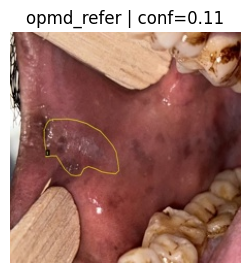

{
  "category": "opmd_refer",
  "risk_level": "refer",
  "source_label": "opmd",
  "explanation": "The cropped oral mucosal region corresponds to an oral potentially malignant disorder category in the source dataset. This type of finding should be referred for clinical evaluation because OPMD lesions may require monitoring, biopsy, or specialist review.",
  "recommendation": "Refer for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


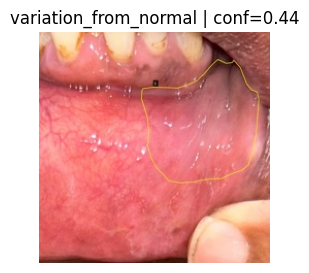

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


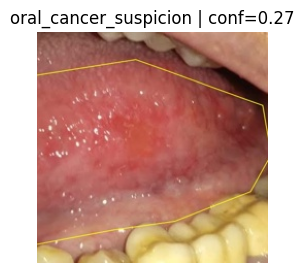

{
  "category": "oral_cancer_suspicion",
  "risk_level": "urgent_refer",
  "source_label": "oral_cancer",
  "explanation": "The cropped oral mucosal region corresponds to an oral cancer category in the source dataset. This should be treated as an urgent referral case for clinical examination and possible biopsy.",
  "recommendation": "Urgent referral for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


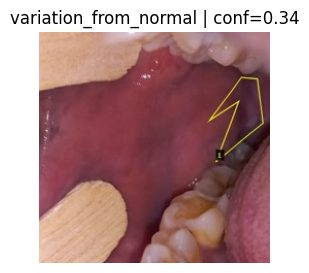

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


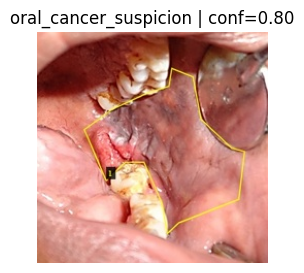

{
  "category": "oral_cancer_suspicion",
  "risk_level": "urgent_refer",
  "source_label": "oral_cancer",
  "explanation": "The cropped oral mucosal region corresponds to an oral cancer category in the source dataset. This should be treated as an urgent referral case for clinical examination and possible biopsy.",
  "recommendation": "Urgent referral for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


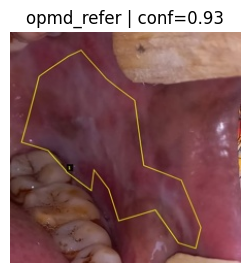

{
  "category": "opmd_refer",
  "risk_level": "refer",
  "source_label": "opmd",
  "explanation": "The cropped oral mucosal region corresponds to an oral potentially malignant disorder category in the source dataset. This type of finding should be referred for clinical evaluation because OPMD lesions may require monitoring, biopsy, or specialist review.",
  "recommendation": "Refer for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


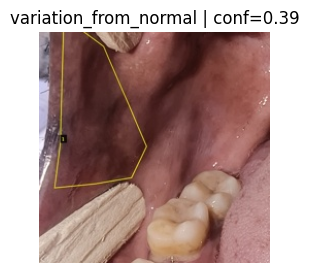

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


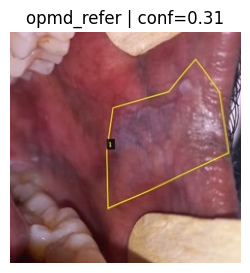

{
  "category": "opmd_refer",
  "risk_level": "refer",
  "source_label": "opmd",
  "explanation": "The cropped oral mucosal region corresponds to an oral potentially malignant disorder category in the source dataset. This type of finding should be referred for clinical evaluation because OPMD lesions may require monitoring, biopsy, or specialist review.",
  "recommendation": "Refer for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


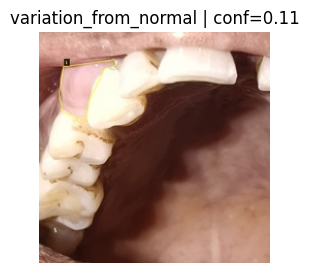

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


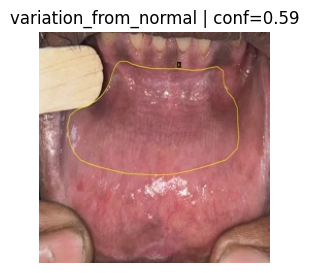

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


In [ ]:
import json
import random
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

JSONL_PATH = "/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_all.jsonl"

records = []

with open(JSONL_PATH, "r", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

print("Records:", len(records))

sample = random.sample(records, min(10, len(records)))

for r in sample:
    img_path = r["image"]
    assistant_content = json.loads(r["messages"][1]["content"])

    img = Image.open(img_path).convert("RGB")

    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"{assistant_content['category']} | conf={r['metadata']['detector_confidence']:.2f}"
    )
    plt.show()

    print(json.dumps(assistant_content, indent=2))
    print("-" * 80)

In [ ]:
CSV_OUT = "/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_dataset.csv"

flat_rows = []

for r in records:
    payload = json.loads(r["messages"][1]["content"])

    flat_rows.append({
        "image": r["image"],
        "split": r["metadata"]["split"],
        "source_class": r["metadata"]["source_class"],
        "category": payload["category"],
        "risk_level": payload["risk_level"],
        "recommendation": payload["recommendation"],
        "detector_confidence": r["metadata"]["detector_confidence"],
        "source_image": r["metadata"]["source_image"],
    })

flat_df = pd.DataFrame(flat_rows)
flat_df.to_csv(CSV_OUT, index=False)

print("Saved CSV:", CSV_OUT)
print(flat_df.head())
print("\nClass counts:")
print(flat_df["category"].value_counts())

Saved CSV: /content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_dataset.csv
                                               image  split  \
0  /content/drive/MyDrive/oral_lesion_crops_224_a...  train   
1  /content/drive/MyDrive/oral_lesion_crops_224_a...  train   
2  /content/drive/MyDrive/oral_lesion_crops_224_a...  train   
3  /content/drive/MyDrive/oral_lesion_crops_224_a...  train   
4  /content/drive/MyDrive/oral_lesion_crops_224_a...  train   

            source_class               category       risk_level  \
0  variation_from_normal  variation_from_normal  low_to_moderate   
1  variation_from_normal  variation_from_normal  low_to_moderate   
2                   opmd             opmd_refer            refer   
3  variation_from_normal  variation_from_normal  low_to_moderate   
4  variation_from_normal  variation_from_normal  low_to_moderate   

                                      recommendation  detector_confidence  \
0  Monitor and seek clinical re

Total records: 364
Missing image files: 0
First missing: []


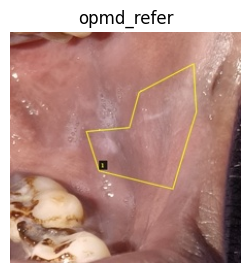

{
  "category": "opmd_refer",
  "risk_level": "refer",
  "source_label": "opmd",
  "explanation": "The cropped oral mucosal region corresponds to an oral potentially malignant disorder category in the source dataset. This type of finding should be referred for clinical evaluation because OPMD lesions may require monitoring, biopsy, or specialist review.",
  "recommendation": "Refer for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


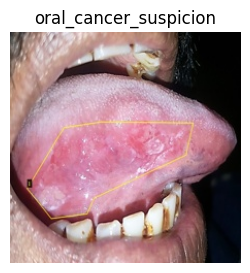

{
  "category": "oral_cancer_suspicion",
  "risk_level": "urgent_refer",
  "source_label": "oral_cancer",
  "explanation": "The cropped oral mucosal region corresponds to an oral cancer category in the source dataset. This should be treated as an urgent referral case for clinical examination and possible biopsy.",
  "recommendation": "Urgent referral for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


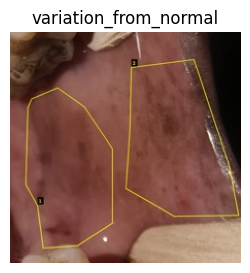

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


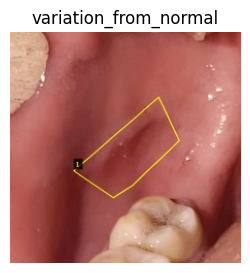

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


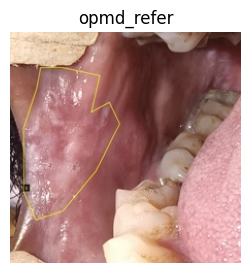

{
  "category": "opmd_refer",
  "risk_level": "refer",
  "source_label": "opmd",
  "explanation": "The cropped oral mucosal region corresponds to an oral potentially malignant disorder category in the source dataset. This type of finding should be referred for clinical evaluation because OPMD lesions may require monitoring, biopsy, or specialist review.",
  "recommendation": "Refer for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


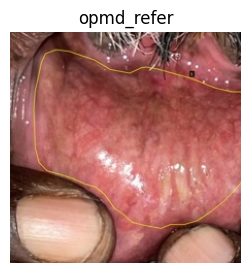

{
  "category": "opmd_refer",
  "risk_level": "refer",
  "source_label": "opmd",
  "explanation": "The cropped oral mucosal region corresponds to an oral potentially malignant disorder category in the source dataset. This type of finding should be referred for clinical evaluation because OPMD lesions may require monitoring, biopsy, or specialist review.",
  "recommendation": "Refer for clinical evaluation.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


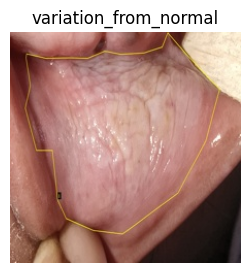

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


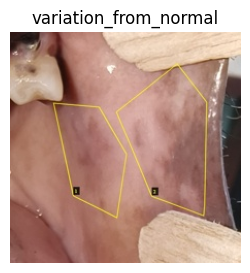

{
  "category": "variation_from_normal",
  "risk_level": "low_to_moderate",
  "source_label": "variation_from_normal",
  "explanation": "The cropped oral mucosal region corresponds to a variation-from-normal category in the source dataset. It should be interpreted cautiously. If the finding is painful, enlarging, bleeding, or persists for more than two weeks, clinical review is recommended.",
  "recommendation": "Monitor and seek clinical review if persistent, painful, enlarging, or bleeding.",
  "disclaimer": "This is a screening-support output, not a medical diagnosis."
}
--------------------------------------------------------------------------------


In [ ]:
import json
from pathlib import Path
from PIL import Image
import random
import matplotlib.pyplot as plt

JSONL_PATH = "/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset/gemma_oral_lesion_all.jsonl"

records = []
with open(JSONL_PATH, "r", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

print("Total records:", len(records))

bad = []
for i, r in enumerate(records):
    img_path = Path(r["image"])
    if not img_path.exists():
        bad.append((i, str(img_path)))

print("Missing image files:", len(bad))
print("First missing:", bad[:5])

sample = random.sample(records, min(8, len(records)))

for r in sample:
    img = Image.open(r["image"]).convert("RGB")
    assistant = json.loads(r["messages"][1]["content"])

    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis("off")
    plt.title(assistant["category"])
    plt.show()

    print(json.dumps(assistant, indent=2))
    print("-" * 80)

In [ ]:
import json
import pandas as pd
from pathlib import Path

LABELED_MANIFEST = "/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_labeled.csv"
OUT_DIR = Path("/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset_v2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(LABELED_MANIFEST)
df = df[(df["detected"] == True) & df["crop_path"].notna() & df["source_class"].notna()].copy()
df = df[df["crop_path"].apply(lambda p: Path(str(p)).exists())].copy()

def category(source_class):
    if source_class == "variation_from_normal":
        return "variation_from_normal"
    if source_class == "opmd":
        return "opmd_refer"
    if source_class == "oral_cancer":
        return "oral_cancer_suspicion"
    return "uncertain"

def recommendation(source_class):
    if source_class == "variation_from_normal":
        return "Monitor. Seek review if persistent, painful, enlarging, or bleeding."
    if source_class == "opmd":
        return "Refer for clinical evaluation."
    if source_class == "oral_cancer":
        return "Urgent referral for clinical evaluation."
    return "Retake image or seek clinical review."

def explanation(source_class):
    if source_class == "variation_from_normal":
        return "The crop corresponds to a variation-from-normal mucosal finding in the source dataset."
    if source_class == "opmd":
        return "The crop corresponds to an oral potentially malignant disorder category in the source dataset."
    if source_class == "oral_cancer":
        return "The crop corresponds to an oral cancer category in the source dataset."
    return "The finding is uncertain."

def make_record(row):
    source_class = row["source_class"]
    crop_path = str(row["crop_path"])

    answer = {
        "category": category(source_class),
        "recommendation": recommendation(source_class),
        "brief_reason": explanation(source_class),
        "disclaimer": "Screening support only, not a diagnosis."
    }

    return {
        "image": crop_path,
        "messages": [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": (
                            "You are an oral screening assistant. Analyze the cropped oral mucosal image. "
                            "Return JSON with category, recommendation, brief_reason, and disclaimer. "
                            "Allowed categories: variation_from_normal, opmd_refer, oral_cancer_suspicion."
                        )
                    },
                    {
                        "type": "image",
                        "image": crop_path
                    }
                ]
            },
            {
                "role": "assistant",
                "content": json.dumps(answer, ensure_ascii=False)
            }
        ],
        "metadata": {
            "split": str(row["split"]),
            "source_class": str(source_class),
            "crop_path": crop_path,
            "detector_confidence": float(row["confidence"]),
        }
    }

records = [make_record(row) for _, row in df.iterrows()]

def write_jsonl(path, items):
    with open(path, "w", encoding="utf-8") as f:
        for item in items:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")

write_jsonl(OUT_DIR / "all.jsonl", records)

for split in ["train", "val", "test"]:
    split_records = [r for r in records if r["metadata"]["split"] == split]
    write_jsonl(OUT_DIR / f"{split}.jsonl", split_records)
    print(split, len(split_records))

print("Saved to:", OUT_DIR)

train 244
val 55
test 65
Saved to: /content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset_v2


In [ ]:
import json
from collections import Counter

TRAIN_JSONL = "/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset_v2/train.jsonl"
VAL_JSONL = "/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset_v2/val.jsonl"
TEST_JSONL = "/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset_v2/test.jsonl"

def count_categories(path):
    c = Counter()
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            payload = json.loads(r["messages"][1]["content"])
            c[payload["category"]] += 1
    return c

print("Train:", count_categories(TRAIN_JSONL))
print("Val:", count_categories(VAL_JSONL))
print("Test:", count_categories(TEST_JSONL))

Train: Counter({'variation_from_normal': 142, 'opmd_refer': 89, 'oral_cancer_suspicion': 13})
Val: Counter({'variation_from_normal': 37, 'opmd_refer': 18})
Test: Counter({'opmd_refer': 39, 'variation_from_normal': 22, 'oral_cancer_suspicion': 4})


#Create binary Gemma JSONL

In [ ]:
import json
import pandas as pd
from pathlib import Path
from collections import Counter

LABELED_MANIFEST = "/content/drive/MyDrive/oral_lesion_crops_224_all/crop_manifest_labeled.csv"

OUT_DIR = Path("/content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset_binary")
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(LABELED_MANIFEST)

df = df[
    (df["detected"] == True) &
    df["crop_path"].notna() &
    df["source_class"].notna()
].copy()

df = df[df["crop_path"].apply(lambda p: Path(str(p)).exists())].copy()


def binary_category(source_class):
    if source_class == "variation_from_normal":
        return "low_risk_or_variation"

    if source_class in ["opmd", "oral_cancer"]:
        return "refer_for_clinical_review"

    return "uncertain"


def recommendation(source_class):
    if source_class == "variation_from_normal":
        return (
            "Monitor the finding. Seek clinical review if it persists for more than two weeks, "
            "becomes painful, enlarges, bleeds, or causes functional difficulty."
        )

    if source_class == "opmd":
        return (
            "Refer for clinical evaluation. This crop belongs to an oral potentially malignant disorder category "
            "in the source dataset and may require monitoring, specialist review, or biopsy."
        )

    if source_class == "oral_cancer":
        return (
            "Urgent referral for clinical evaluation is recommended. This crop belongs to an oral cancer category "
            "in the source dataset and requires professional assessment."
        )

    return "Retake the image or seek clinical review if symptoms persist."


def brief_reason(source_class):
    if source_class == "variation_from_normal":
        return (
            "The crop corresponds to a variation-from-normal mucosal finding in the source dataset. "
            "It is not treated as an urgent referral category by default."
        )

    if source_class == "opmd":
        return (
            "The crop corresponds to an oral potentially malignant disorder category in the source dataset. "
            "Such findings should be clinically reviewed."
        )

    if source_class == "oral_cancer":
        return (
            "The crop corresponds to an oral cancer category in the source dataset. "
            "This should be treated as high-priority clinical referral."
        )

    return "The visual category is uncertain."


def make_record(row):
    source_class = str(row["source_class"])
    crop_path = str(row["crop_path"])

    answer = {
        "category": binary_category(source_class),
        "source_subtype": source_class,
        "recommendation": recommendation(source_class),
        "brief_reason": brief_reason(source_class),
        "disclaimer": "Screening support only, not a medical diagnosis."
    }

    return {
        "image": crop_path,
        "messages": [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": (
                            "You are an oral screening assistant. Analyze the cropped oral mucosal image. "
                            "Return JSON only with category, source_subtype, recommendation, brief_reason, and disclaimer. "
                            "Allowed categories: low_risk_or_variation, refer_for_clinical_review. "
                            "Do not claim a definitive diagnosis."
                        )
                    },
                    {
                        "type": "image",
                        "image": crop_path
                    }
                ]
            },
            {
                "role": "assistant",
                "content": json.dumps(answer, ensure_ascii=False)
            }
        ],
        "metadata": {
            "split": str(row["split"]),
            "source_class": source_class,
            "binary_category": binary_category(source_class),
            "crop_path": crop_path,
            "detector_confidence": float(row["confidence"]),
        }
    }


records = [make_record(row) for _, row in df.iterrows()]


def write_jsonl(path, items):
    with open(path, "w", encoding="utf-8") as f:
        for item in items:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")


write_jsonl(OUT_DIR / "all.jsonl", records)

for split in ["train", "val", "test"]:
    split_records = [r for r in records if r["metadata"]["split"] == split]
    write_jsonl(OUT_DIR / f"{split}.jsonl", split_records)

    counts = Counter([r["metadata"]["binary_category"] for r in split_records])
    print(split, len(split_records), counts)

print("Saved binary Gemma dataset to:", OUT_DIR)

train 244 Counter({'low_risk_or_variation': 142, 'refer_for_clinical_review': 102})
val 55 Counter({'low_risk_or_variation': 37, 'refer_for_clinical_review': 18})
test 65 Counter({'refer_for_clinical_review': 43, 'low_risk_or_variation': 22})
Saved binary Gemma dataset to: /content/drive/MyDrive/oral_lesion_crops_224_all/gemma_dataset_binary


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/oral_yolo_runs")
# change if local:
# ROOT = Path("/home/sach/oral_yolo_runs")

rows = []

for run in ROOT.iterdir():

    csv_path = run / "results.csv"

    if not csv_path.exists():
        continue

    try:
        df = pd.read_csv(csv_path)

        last = df.iloc[-1]

        rows.append({
            "run": run.name,
            "precision": last.get("metrics/precision(B)", None),
            "recall": last.get("metrics/recall(B)", None),
            "mAP50": last.get("metrics/mAP50(B)", None),
            "mAP50_95": last.get("metrics/mAP50-95(B)", None),
            "fitness": last.get("fitness", None),
        })

    except Exception as e:
        print("ERROR:", run.name, e)

ranked = pd.DataFrame(rows)

if len(ranked) == 0:
    print("No YOLO results found.")
else:

    ranked = ranked.sort_values(
        by=["recall", "mAP50"],
        ascending=False
    )

    print("\n===== BEST YOLO RUNS =====\n")
    print(ranked.to_string(index=False))


===== BEST YOLO RUNS =====

                             run  precision  recall   mAP50  mAP50_95 fitness
lesion_cropper_yolo11n_recall_v2    0.38606 0.43750 0.32163   0.14160    None
        lesion_cropper_yolo11n-6    0.66007 0.41667 0.45591   0.19265    None
          lesion_cropper_yolo11s    0.39201 0.41641 0.32168   0.11946    None
